# Advanced Ray Train on Anyscale: Mid-Epoch Resumption, Async Checkpointing, and Async Validation

In this tutorial, you build on the basics of Ray Train to **remove common performance and reliability bottlenecks in distributed deep learning training**. Instead of optimizing for model accuracy, you focus on keeping GPUs busy, minimizing wasted work, and making training resilient to failures.

In typical distributed training systems, GPUs sit idle or repeat work because of:
- **Failure recovery**, where a worker crash forces you to redo every batch since the start of the epoch.
- **Synchronous checkpointing**, where training blocks while checkpoints upload to remote storage.
- **Synchronous validation**, where training GPUs stop making progress while validation runs.

Ray Train on Anyscale addresses each of these, and you implement all three end to end in this notebook.

## What you learn

### 1. Mid-epoch resumption (the main event)
You recover from a worker crash **without restarting the epoch**. You checkpoint the position of the **Ray Data iterator** together with the model and optimizer, so training resumes from the last checkpoint with the rows it has not seen yet. You then crash a worker on purpose and verify the recovery. For more details, see the Anyscale [mid-epoch resumption documentation](https://docs.anyscale.com/runtime/mid-epoch-resumption).

### 2. Asynchronous checkpointing
You upload checkpoints to persistent storage **in the background**, so the training loop continues instead of waiting on storage I/O. For more details, see the Ray Train [checkpointing documentation](https://docs.ray.io/en/latest/train/user-guides/checkpoints.html).

### 3. Asynchronous validation
You run validation **out of band** on a separate GPU with Ray Data batch inference, while the training workers move on to the next epoch. For more details, see the Ray Train [asynchronous validation documentation](https://docs.ray.io/en/latest/train/user-guides/asynchronous-validation.html).

## Tutorial overview

In this notebook, you:
1. Write MNIST to Parquet with a stable row ID and stream it with Ray Data.
2. Learn the three ingredients of mid-epoch resumption.
3. Define an asynchronous validation function.
4. Write a training loop that checkpoints mid-epoch, uploads asynchronously, and triggers validation.
5. Crash a training worker in the middle of an epoch and watch Ray Train resume from the last checkpoint.
6. Verify the recovery from the reported metrics, then load the final checkpoint and run inference.

## Prerequisites

- This tutorial assumes you know basic Ray Train concepts. If you don't, start with the [ray train documentation](https://docs.ray.io/en/latest/train/train.html).
- You need an Anyscale workspace with **3 GPUs** of any type: 2 for training workers and 1 for asynchronous validation.
- The dependencies are listed in `requirements.txt` and the `Dockerfile` next to this notebook.

## Imports

In addition to standard PyTorch components, you import the Ray Train APIs behind the three features:

- **`DataConfig`** and **`DatasetCheckpointConfig`** enable checkpointing of the Ray Data iterator, which is what makes mid-epoch resumption possible.
- **`CheckpointUploadMode`** enables asynchronous checkpoint uploads.
- **`ValidationConfig`** registers the function that Ray Train runs asynchronously to validate checkpoints.
- **`FailureConfig`** tells Ray Train to recover from worker failures automatically.

In [1]:
import json
import os
import signal
import tempfile
from datetime import datetime
from typing import Any, Dict, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.datasets import MNIST
from torchvision.models import resnet18

import ray
import ray.train
import ray.train.torch
from ray.train import (
    Checkpoint,
    CheckpointConsistencyMode,
    CheckpointUploadMode,      # Asynchronous checkpoint uploads
    DataConfig,                # Ray Data ingest configuration
    DatasetCheckpointConfig,   # Ray Data iterator checkpointing (mid-epoch resumption)
    FailureConfig,             # Automatic failure recovery
    RunConfig,
    ScalingConfig,
    ValidationConfig,          # Asynchronous validation
)
from ray.train.torch import TorchTrainer

# Keep the notebook output readable: hide Ray Data progress bars.
ray.data.DataContext.get_current().enable_progress_bars = False

print("Ray version:", ray.__version__)

Ray version: 2.60.0


## Configure shared storage

In a multi-node cluster, every worker needs to read the dataset and write checkpoints, so everything lives on **shared storage**. Here you use the cluster storage that Anyscale mounts on every node. See the documentation for [all available storage options](https://docs.anyscale.com/configuration/storage).

You use shared storage for:
- The raw MNIST download.
- The Parquet datasets that Ray Data streams during training and validation.
- The Ray Train run directory, which holds model checkpoints and the Ray Data iterator checkpoints.
- A small event log that the training workers write, so that you can read a clean timeline of the run afterward.

In [2]:
SHARED_ROOT = "/mnt/cluster_storage"

# Raw MNIST download
DATA_ROOT = os.path.join(SHARED_ROOT, "data")

# Everything this tutorial creates lives under one directory
TUTORIAL_ROOT = os.path.join(SHARED_ROOT, "ray_train_async_tutorial")
TRAIN_PARQUET = os.path.join(TUTORIAL_ROOT, "mnist_parquet", "train")
VAL_PARQUET = os.path.join(TUTORIAL_ROOT, "mnist_parquet", "val")
RUN_STORAGE = os.path.join(TUTORIAL_ROOT, "runs")
EVENT_LOG_DIR = os.path.join(TUTORIAL_ROOT, "event_logs")

os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(RUN_STORAGE, exist_ok=True)
os.makedirs(EVENT_LOG_DIR, exist_ok=True)

print("TRAIN_PARQUET:", TRAIN_PARQUET)
print("VAL_PARQUET:  ", VAL_PARQUET)
print("RUN_STORAGE:  ", RUN_STORAGE)

TRAIN_PARQUET: /mnt/cluster_storage/ray_train_async_tutorial/mnist_parquet/train
VAL_PARQUET:   /mnt/cluster_storage/ray_train_async_tutorial/mnist_parquet/val
RUN_STORAGE:   /mnt/cluster_storage/ray_train_async_tutorial/runs


## Write MNIST to Parquet with a stable row ID

To resume in the middle of an epoch, Ray Data needs to know **which rows the training workers already consumed**. It tracks this with a column of unique row IDs, so you write an `id` column into the Parquet files.

You also hold out every tenth image as a validation set. Doing the split once, at write time, keeps the training pipeline simple.

In [3]:
def write_mnist_parquet() -> None:
    """Write MNIST to Parquet on shared storage, with a unique `id` per row."""
    if os.path.exists(TRAIN_PARQUET) and os.path.exists(VAL_PARQUET):
        print("Parquet datasets already exist, skipping.")
        return

    mnist = MNIST(root=DATA_ROOT, train=True, download=True)
    df = pd.DataFrame(
        {
            "id": np.arange(len(mnist), dtype=np.int64),   # Unique, stable row ID
            "image": list(mnist.data.numpy()),             # 28x28 uint8 arrays
            "label": mnist.targets.numpy().astype(np.int64),
        }
    )

    # Hold out every tenth row for validation.
    is_val = df["id"] % 10 == 0
    ray.data.from_pandas(df[~is_val]).repartition(8).write_parquet(TRAIN_PARQUET)
    ray.data.from_pandas(df[is_val]).repartition(2).write_parquet(VAL_PARQUET)
    print(f"Wrote {(~is_val).sum():,} training rows and {is_val.sum():,} validation rows.")


write_mnist_parquet()

Parquet datasets already exist, skipping.


## Create the streaming training dataset

You define the training dataset with Ray Data. The pipeline is **lazy**: Ray Data reads and preprocesses rows only as the training workers consume them.

For mid-epoch resumption, the pipeline needs to follow two rules:
- **Use map-style transformations only**, such as `map`, `map_batches`, and `filter`. These transform rows without changing which rows exist.
- **Keep the `id` column** through every transformation, so each row that reaches a training worker still carries its ID.

In [4]:
def preprocess(batch: Dict[str, np.ndarray]) -> Dict[str, np.ndarray]:
    """Scale images to [-1, 1] and add a channel dimension. The `id` column passes through."""
    images = batch["image"].astype(np.float32) / 255.0
    batch["image"] = ((images - 0.5) / 0.5)[:, None, :, :]
    return batch


train_ds = ray.data.read_parquet(TRAIN_PARQUET).map_batches(preprocess)

NUM_TRAIN_ROWS = train_ds.count()
print(f"Training rows: {NUM_TRAIN_ROWS:,}")
print(train_ds.schema())

2026-11-10 05:58:16,666	INFO worker.py:1841 -- Connecting to existing Ray cluster at address: 10.0.66.130:6379...


2026-11-10 05:58:16,703	INFO worker.py:2029 -- Connected to Ray cluster. View the dashboard at https://session-q31byycvdcqlull5wafx6jyk61.i.anyscaleuserdata.com 


2026-11-10 05:58:16,706	INFO packaging.py:456 -- Pushing file package 'gcs://_ray_pkg_277fdb5ccbaacc2de59d964e29ee1fbaf3725d07.zip' (0.20MiB) to Ray cluster...


2026-11-10 05:58:16,708	INFO packaging.py:469 -- Successfully pushed file package 'gcs://_ray_pkg_277fdb5ccbaacc2de59d964e29ee1fbaf3725d07.zip'.


2026-11-10 05:58:16,914	INFO streaming_executor.py:222 -- Starting execution of Dataset dataset_034vCI5vmQpKE5DUDVqhvs_0. Full logs are in /tmp/ray/session_2026-11-10_05-02-25_907037_3360/logs/ray-data


2026-11-10 05:58:16,915	INFO streaming_executor.py:223 -- Execution plan of Dataset dataset_034vCI5vmQpKE5DUDVqhvs_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ListFiles] -> TaskPoolMapOperator[ReadFiles] -> TaskPoolMapOperator[MapBatches(preprocess)->Project] -> AggregateNumRows[AggregateNumRows]


... (3 outputs left out)

2026-11-10 05:58:23,175	INFO streaming_executor.py:223 -- Execution plan of Dataset dataset_034vCIFuIKoEGpEy4j9bZT_0: InputDataBuffer[Input] -> TaskPoolMapOperator[ListFiles] -> TaskPoolMapOperator[ReadFiles] -> TaskPoolMapOperator[MapBatches(preprocess)] -> LimitOperator[limit=1]


Training rows: 54,000


2026-11-10 05:58:23,563	INFO streaming_executor.py:391 -- ✔️  Dataset dataset_034vCIFuIKoEGpEy4j9bZT_0 execution finished in 0.39 seconds


Column  Type
------  ----
id      int64
image   ArrowTensorTypeV2(shape=(1, 28, 28), dtype=float)
label   int64


## Define the model

You use a ResNet-18 adapted for single-channel MNIST images. The model is intentionally simple so that you can focus on the behavior of the training system.

In [5]:
def build_model() -> nn.Module:
    model = resnet18(num_classes=10)
    # MNIST images have one channel instead of three.
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    return model

## How mid-epoch resumption works

A standard fault-tolerant training loop checkpoints the model and optimizer. After a failure, it reloads them and **restarts the data from the beginning of the epoch**, because it has no record of which rows it already used. Every batch between the start of the epoch and the crash is repeated.

Mid-epoch resumption adds the missing piece: the checkpoint also records **the position of the data iterator**. In this tutorial, each worker trains on 211 batches per epoch, you checkpoint every 50 batches, and you crash a worker at batch 120 of the second epoch:

```text
Epoch 1, as seen by one training worker (211 batches)

batch   0         50        100    120                              211
        |----------|---------|------X
                   ^         ^      ^
               checkpoint checkpoint crash

Without mid-epoch resumption:  restart at batch 0    -> repeat 120 batches
With mid-epoch resumption:     restart at batch 100  -> repeat  20 batches
```

On MNIST the difference is a few seconds. On a dataset where one epoch takes hours or days, it's the difference between losing minutes and losing the whole epoch.

### The three ingredients

Mid-epoch resumption takes three small changes to a standard Ray Train loop:

| | What you do | Where |
|---|---|---|
| **1. Enable** | Tell Ray Train which column holds the row ID: `DatasetCheckpointConfig(id_column="id")`. | Trainer configuration |
| **2. Save** | Call `train_shard.state_dict()` and store the result in the same checkpoint as the model. | Training loop, at every checkpoint |
| **3. Restore** | Pass the saved state back: `ray.train.get_dataset_shard("train", state_dict=...)`. | Training loop, at startup |

The next cell covers the **save** and **restore** halves of the checkpoint. A checkpoint in this tutorial has three files:

- `model.pt` and `optim.pt`: the model and optimizer state, as in any PyTorch checkpoint.
- `resume_state.json`: where to resume. It holds your own progress counters and the Ray Data iterator state.

In [6]:
def save_checkpoint(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    progress: Dict[str, int],
    data_state: Dict[str, Any],
) -> Checkpoint:
    """Write the model, the optimizer, and the position in the data to a local directory."""
    checkpoint_dir = tempfile.mkdtemp(prefix="ray_train_ckpt_")
    torch.save(model.state_dict(), os.path.join(checkpoint_dir, "model.pt"))
    torch.save(optimizer.state_dict(), os.path.join(checkpoint_dir, "optim.pt"))
    with open(os.path.join(checkpoint_dir, "resume_state.json"), "w") as f:
        json.dump({"progress": progress, "data_state": data_state}, f, indent=2)
    return Checkpoint.from_directory(checkpoint_dir)


def load_checkpoint(
    checkpoint: Checkpoint,
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
) -> Tuple[Dict[str, int], Dict[str, Any]]:
    """Restore the model and optimizer in place. Return the progress counters and data state."""
    with checkpoint.as_directory() as checkpoint_dir:
        model.load_state_dict(torch.load(os.path.join(checkpoint_dir, "model.pt"), map_location="cpu"))
        optimizer.load_state_dict(torch.load(os.path.join(checkpoint_dir, "optim.pt"), map_location="cpu"))
        with open(os.path.join(checkpoint_dir, "resume_state.json")) as f:
            resume_state = json.load(f)
    return resume_state["progress"], resume_state["data_state"]

## Define the asynchronous validation function

Validation usually runs inline: training stops, the training GPUs evaluate the model, and training starts again. With asynchronous validation, Ray Train runs a **validation function** in a separate Ray task whenever you ask it to validate a checkpoint, and the training workers continue with the next epoch.

A validation function takes the checkpoint to validate, plus any keyword arguments you configure, and returns a dictionary of metrics. Ray Train attaches those metrics to the checkpoint.

Here you implement validation as **Ray Data batch inference**: a `Predictor` loads the model from the checkpoint onto a GPU, and `map_batches` streams the validation set through it. Because validation requests its own GPU, it runs on the third GPU in the cluster while the two training workers keep training. Validation often needs less compute than training, so at scale you can place it on smaller or cheaper GPUs than the ones you train on.

In [7]:
class Predictor:
    """Loads the model from a checkpoint once, then scores batches on a GPU."""

    def __init__(self, checkpoint: Checkpoint):
        self.model = build_model()
        with checkpoint.as_directory() as checkpoint_dir:
            state_dict = torch.load(os.path.join(checkpoint_dir, "model.pt"), map_location="cpu")
        self.model.load_state_dict(state_dict)
        self.model.cuda().eval()

    def __call__(self, batch: Dict[str, np.ndarray]) -> Dict[str, np.ndarray]:
        images = torch.as_tensor(batch["image"], device="cuda")
        labels = torch.as_tensor(batch["label"], device="cuda")
        with torch.no_grad():
            predictions = self.model(images).argmax(dim=1)
        return {"correct": (predictions == labels).cpu().numpy()}


def validate_fn(checkpoint: Checkpoint, val_path: str, batch_size: int) -> Dict[str, float]:
    """Validate one checkpoint. Ray Train runs this function in a separate Ray task."""
    ray.data.DataContext.get_current().enable_progress_bars = False

    val_ds = ray.data.read_parquet(val_path).map_batches(preprocess)
    val_ds.set_name("validation")

    results = val_ds.map_batches(
        Predictor,
        fn_constructor_kwargs={"checkpoint": checkpoint},
        batch_size=batch_size,
        num_gpus=1,                                     # Validation gets its own GPU
        compute=ray.data.ActorPoolStrategy(size=1),     # One Predictor replica
    )
    return {"val_accuracy": results.mean("correct")}

## Helpers for the demonstration

The training loop uses two small helpers that exist only to make the recovery easy to observe.

**An event log.** Ray Train prints a lot of useful detail during a run, and even more during a failure. `log_event` prints a message and also appends it to a file on shared storage, so that after the run you can read the handful of events that matter as a clean timeline.

**A simulated crash.** To see mid-epoch resumption work, you need a failure in the middle of an epoch. `maybe_simulate_crash` makes the last-ranked training worker kill its own process with `SIGKILL` at a chosen epoch and batch. `SIGKILL` gives the process no chance to clean up, which mimics what an out-of-memory kill, a hardware fault, or a spot preemption does to a training worker.

Two details keep the demonstration clean:
- The crash happens only on the **first attempt**. After Ray Train restarts the workers, they train to completion.
- Checkpoints upload in the background, so the helper first waits for in-flight uploads to finish. This makes the run resume from the same checkpoint every time you run the notebook. A real failure doesn't wait, and Ray Train resumes from the latest checkpoint that finished uploading.

In [8]:
def log_event(message: str) -> None:
    """Print a message and append it to this run's event log on shared storage."""
    ctx = ray.train.get_context()
    line = f"[rank {ctx.get_world_rank()}] {message}"
    print(line, flush=True)
    with open(os.path.join(EVENT_LOG_DIR, f"{ctx.get_experiment_name()}.log"), "a") as f:
        f.write(line + "\n")


def maybe_simulate_crash(config: Dict[str, Any], epoch: int, batch: int, is_first_attempt: bool) -> None:
    """Kill the last-ranked training worker at the configured epoch and batch."""
    crash_at = config.get("simulate_crash_at")
    ctx = ray.train.get_context()

    if not crash_at or not is_first_attempt:
        return
    if ctx.get_world_rank() != ctx.get_world_size() - 1:
        return
    if (epoch, batch) != (crash_at["epoch"], crash_at["batch"]):
        return

    # Wait for background checkpoint uploads so that the demo is reproducible.
    ray.train.get_all_reported_checkpoints(consistency_mode=CheckpointConsistencyMode.COMMITTED)

    log_event(f"epoch {epoch} | batch {batch:>3} | WORKER CRASH (simulated with SIGKILL)")
    os.kill(os.getpid(), signal.SIGKILL)

## Implement the training loop

The training loop below is a standard Ray Train loop with the three features added. Read it in four parts, which match the numbered comments in the code:

**Part 1: Restore.** If Ray Train hands the worker a checkpoint, the worker loads the model, the optimizer, its progress counters, and the saved data state. On a fresh start there is no checkpoint and the data state is `None`.

**Part 2: Position the data.** The worker passes the data state to `ray.train.get_dataset_shard`. With a saved state, Ray Data skips the rows that the workers consumed before the checkpoint. With `None`, iteration starts from the beginning.

**Part 3: Train and checkpoint mid-epoch.** Every `checkpoint_every_n_batches` batches, each worker captures the iterator position with `train_shard.state_dict()`. All workers call it at the same step, so that the saved position is consistent across the whole worker group. Rank 0 then saves the checkpoint and reports it with `CheckpointUploadMode.ASYNC`, so the upload happens in the background while training continues.

**Part 4: End of epoch.** The workers report one more checkpoint, which says "resume at the start of the next epoch", and rank 0 sets `validation=True` to trigger asynchronous validation of that checkpoint.

The loop tracks three progress counters: `epoch`, `batch` (batches this worker completed in the current epoch), and `rows_seen` (rows this worker trained on in the current epoch). You use them later to verify the recovery.

In [9]:
def train_loop_per_worker(config: Dict[str, Any]) -> None:
    ctx = ray.train.get_context()
    rank = ctx.get_world_rank()

    # Model and optimizer. `prepare_model` moves the model to the GPU and wraps it for DDP.
    model = ray.train.torch.prepare_model(build_model())
    module = model.module if hasattr(model, "module") else model
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    criterion = nn.CrossEntropyLoss()
    batch_size = config["global_batch_size"] // ctx.get_world_size()

    # ------------------------------------------------------------------
    # Part 1: Restore from the latest checkpoint, if there is one.
    # ------------------------------------------------------------------
    progress = {"epoch": 0, "batch": 0, "rows_seen": 0}
    data_state = None   # None means "start from the beginning of the data"

    checkpoint = ray.train.get_checkpoint()
    is_first_attempt = checkpoint is None
    if checkpoint:
        progress, data_state = load_checkpoint(checkpoint, module, optimizer)

    start_epoch, batch, rows_seen = progress["epoch"], progress["batch"], progress["rows_seen"]

    if rank == 0:
        if is_first_attempt:
            log_event("No checkpoint found. Starting from epoch 0, batch 0.")
        else:
            log_event(
                f"epoch {start_epoch} | batch {batch:>3} | RESUMED from checkpoint. "
                f"Skipping the {rows_seen:,} rows this worker already trained on in this epoch."
            )

    # ------------------------------------------------------------------
    # Part 2: Position the data iterator where the checkpoint left off.
    # ------------------------------------------------------------------
    train_shard = ray.train.get_dataset_shard("train", state_dict=data_state)

    def report_checkpoint(metrics: Dict[str, Any], resume_from: Dict[str, int], validation: bool = False) -> None:
        # Every worker captures the data iterator position at the same step.
        data_state = train_shard.state_dict()

        if rank == 0:
            # Rank 0 saves the model, optimizer, and data position in one checkpoint.
            # ASYNC upload: Ray Train copies it to shared storage in the background.
            ray.train.report(
                metrics,
                checkpoint=save_checkpoint(module, optimizer, resume_from, data_state),
                checkpoint_upload_mode=CheckpointUploadMode.ASYNC,
                validation=validation,
            )
        else:
            # Other workers still call report so that all workers stay in sync.
            ray.train.report({}, checkpoint=None)

    for epoch in range(start_epoch, config["epochs"]):
        model.train()

        # --------------------------------------------------------------
        # Part 3: Train, and checkpoint every N batches.
        # --------------------------------------------------------------
        for data in train_shard.iter_torch_batches(batch_size=batch_size):
            loss = criterion(model(data["image"]), data["label"])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batch += 1
            rows_seen += len(data["id"])

            if batch % config["checkpoint_every_n_batches"] == 0:
                report_checkpoint(
                    metrics={"epoch": epoch, "batch": batch, "rows_seen": rows_seen, "train_loss": loss.item()},
                    resume_from={"epoch": epoch, "batch": batch, "rows_seen": rows_seen},
                )
                if rank == 0:
                    log_event(f"epoch {epoch} | batch {batch:>3} | mid-epoch checkpoint")

            maybe_simulate_crash(config, epoch, batch, is_first_attempt)

        # --------------------------------------------------------------
        # Part 4: End of epoch. Checkpoint and trigger async validation.
        # --------------------------------------------------------------
        if rank == 0:
            log_event(f"epoch {epoch} | batch {batch:>3} | end of epoch, {rows_seen:,} rows trained on. Validation triggered.")

        report_checkpoint(
            metrics={"epoch": epoch, "batch": batch, "rows_seen": rows_seen, "train_loss": loss.item()},
            resume_from={"epoch": epoch + 1, "batch": 0, "rows_seen": 0},
            validation=True,
        )
        batch, rows_seen = 0, 0

### A note on asynchronous checkpointing

With `CheckpointUploadMode.ASYNC`, `ray.train.report` returns as soon as it hands the local checkpoint directory to a background upload, and Ray Train deletes the local copy after the upload finishes. The copy to shared or cloud storage is usually the slow part of checkpointing, and it no longer blocks training.

Writing the checkpoint files to local disk with `torch.save` still happens in the training loop. For most models this is fast. If serialization itself becomes a bottleneck for a very large model, `ray.train.report` also accepts a `checkpoint_upload_fn`, which lets you take control of how the checkpoint reaches storage.

## Configure the trainer

The trainer configuration connects everything:

- **`dataset_config`** is ingredient 1 of mid-epoch resumption. `DatasetCheckpointConfig(id_column="id")` turns on iterator checkpointing for the `train` dataset and names the row ID column. By default, Ray Data stores its iterator checkpoints inside the run directory on shared storage.
- **`validation_config`** registers `validate_fn` and its default keyword arguments. The keyword arguments must be JSON-serializable, so you pass the path of the validation data instead of a dataset object.
- **`scaling_config`** requests two GPU training workers. The third GPU stays free for validation.
- **`failure_config`** allows one automatic recovery. Without it, the crash would end the run.
- **`simulate_crash_at`** schedules the crash for epoch 1, batch 120, which is 20 batches after a mid-epoch checkpoint. Set it to `None` to train without a failure.

The run gets a unique name each time you execute the cell. Ray Train identifies a run by its name and storage path, and a new name guarantees a fresh run instead of a continuation of an earlier one.

In [10]:
NUM_TRAIN_WORKERS = 2
RUN_NAME = f"mnist_mid_epoch_resume_{datetime.now():%Y%m%d_%H%M%S}"

trainer = TorchTrainer(
    train_loop_per_worker=train_loop_per_worker,
    train_loop_config={
        "lr": 1e-4,
        "global_batch_size": 256,
        "epochs": 3,
        "checkpoint_every_n_batches": 50,
        "simulate_crash_at": {"epoch": 1, "batch": 120},
    },
    datasets={"train": train_ds},
    # Mid-epoch resumption: checkpoint the Ray Data iterator, tracking rows by the "id" column.
    dataset_config=DataConfig(
        dataset_checkpoint_configs={"train": DatasetCheckpointConfig(id_column="id")},
    ),
    # Asynchronous validation: the function to run, and its default keyword arguments.
    validation_config=ValidationConfig(
        fn=validate_fn,
        task_config=ray.train.ValidationTaskConfig(
            fn_kwargs={"val_path": VAL_PARQUET, "batch_size": 512},
        ),
    ),
    scaling_config=ScalingConfig(num_workers=NUM_TRAIN_WORKERS, use_gpu=True),
    run_config=RunConfig(
        name=RUN_NAME,
        storage_path=RUN_STORAGE,
        failure_config=FailureConfig(max_failures=1),
    ),
)

print("Run name:", RUN_NAME)

Run name: mnist_mid_epoch_resume_20261110_055823


## Start training

You now launch the run. It trains normally through epoch 0, loses a worker in the middle of epoch 1, recovers, and finishes all three epochs.

The cell output is long, because it includes Ray Train's own logs and the error messages from the crash. Errors such as `WorkerGroupError`, `ActorDiedError`, and failures from the surviving worker when it loses its peer are expected here: they are the crash you asked for. You don't need to read the output line by line. The next cell shows the events that matter.

In [11]:
result = trainer.fit()

(TrainController pid=42710) Requesting resources: {'GPU': 1} * 2
(TrainController pid=42710) /home/ray/anaconda3/lib/python3.11/site-packages/ray/data/_internal/execution/interfaces/execution_options.py:436: RayDeprecationWarning: `ExecutionOptions.exclude_resources` is deprecated and will be removed after January 2027. Use `ExecutionOptions.label_selector` to constrain Ray Data work to labeled nodes.
(TrainController pid=42710)   self.exclude_resources = exclude_resources
(TrainController pid=42710) [State Transition] INITIALIZING -> SCHEDULING.
(TrainController pid=42710) Attempting to start training worker group of size 2 with the following resources: [{'GPU': 1}] * 2


(RayTrainWorker pid=13390, ip=10.0.75.194) Setting up process group for: env:// [rank=0, world_size=2]


(TrainController pid=42710) {"asctime":"2026-11-10 05:58:33,276","levelname":"E","message":"Actor with class name: 'PreemptionWatcher' and ID: 'dda88b41f2bcffda2d451d530a000000' has constructor arguments in the object store and max_restarts > 0. If the arguments in the object store go out of scope or are lost, the actor restart will fail. See https://github.com/ray-project/ray/issues/53727 for more details.","filename":"core_worker.cc","lineno":2465}


(TrainController pid=42710) Started training worker group of size 2: 
(TrainController pid=42710) - (ip=10.0.75.194, pid=13390) world_rank=0, local_rank=0, node_rank=0
(TrainController pid=42710) - (ip=10.0.110.19, pid=12634) world_rank=1, local_rank=0, node_rank=1
(TrainController pid=42710) [State Transition] SCHEDULING -> RUNNING.
(RayTrainWorker pid=13390, ip=10.0.75.194) Moving model to device: cuda:0
(RayTrainWorker pid=13390, ip=10.0.75.194) Wrapping provided model in DistributedDataParallel.


(RayTrainWorker pid=13390, ip=10.0.75.194) [rank 0] No checkpoint found. Starting from epoch 0, batch 0.
(DatasetManager pid=42905) Dataset checkpointing is enabled, but no dataset state passed in via `ray.train.get_dataset_shard('train', state_dict=...)`. Iteration will yield from the beginning. This is expected when starting the run from scratch rather than resuming from a checkpoint.
(DatasetManager pid=42905) /home/ray/anaconda3/lib/python3.11/site-packages/ray/data/_internal/execution/interfaces/execution_options.py:436: RayDeprecationWarning: `ExecutionOptions.exclude_resources` is deprecated and will be removed after January 2027. Use `ExecutionOptions.label_selector` to constrain Ray Data work to labeled nodes.
(DatasetManager pid=42905)   self.exclude_resources = exclude_resources


(RayTrainWorker pid=13390, ip=10.0.75.194) [rank 0] No checkpoint found. Starting from epoch 0, batch 0.


... (72 outputs left out)

(TrainController pid=42710) [State Transition] RUNNING -> SHUTTING_DOWN.


(MapWorker(MapBatches(Predictor)) pid=14231, ip=10.0.75.194) /tmp/ipykernel_42427/390086688.py:12: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)


(run_validation_fn pid=13473, ip=10.0.75.194) ✔️  Dataset validation_034vCL1vszCzhSvoW16tUx_0 execution finished in 6.74 seconds


(TrainController pid=42710) Finished async validation task(s) for checkpoint(s): [Checkpoint(filesystem=local, path=/mnt/cluster_storage/ray_train_async_tutorial/runs/mnist_mid_epoch_resume_20261110_055823/checkpoint_2026-11-10_06-00-09.953732)].
(TrainController pid=42710) Running validations for checkpoint(s): [].
(TrainController pid=42710) Staged validations for checkpoint(s): [].


## Watch the recovery

The event log that the workers wrote is a clean timeline of the run. Read it from top to bottom:

1. The run starts with no checkpoint, at epoch 0, batch 0.
2. Epoch 0 completes with mid-epoch checkpoints at batches 50, 100, 150, and 200.
3. Epoch 1 reaches the checkpoint at batch 100, and then a worker crashes at batch 120.
4. Ray Train restarts the worker group, and the new workers **resume at epoch 1, batch 100**. They don't go back to batch 0.
5. The next checkpoint is at batch 150, and epoch 1 ends at batch 211 with 27,000 rows, the same as the uninterrupted epochs.

The only repeated work is the 20 batches between the last checkpoint and the crash.

In [12]:
with open(os.path.join(EVENT_LOG_DIR, f"{RUN_NAME}.log")) as f:
    print(f.read())

[rank 0] No checkpoint found. Starting from epoch 0, batch 0.
[rank 0] epoch 0 | batch  50 | mid-epoch checkpoint
[rank 0] epoch 0 | batch 100 | mid-epoch checkpoint
[rank 0] epoch 0 | batch 150 | mid-epoch checkpoint
[rank 0] epoch 0 | batch 200 | mid-epoch checkpoint
[rank 0] epoch 0 | batch 211 | end of epoch, 27,000 rows trained on. Validation triggered.
[rank 0] epoch 1 | batch  50 | mid-epoch checkpoint
[rank 0] epoch 1 | batch 100 | mid-epoch checkpoint
[rank 1] epoch 1 | batch 120 | WORKER CRASH (simulated with SIGKILL)
[rank 0] epoch 1 | batch 100 | RESUMED from checkpoint. Skipping the 12,800 rows this worker already trained on in this epoch.
[rank 0] epoch 1 | batch 150 | mid-epoch checkpoint
[rank 0] epoch 1 | batch 200 | mid-epoch checkpoint
[rank 0] epoch 1 | batch 211 | end of epoch, 27,000 rows trained on. Validation triggered.
[rank 0] epoch 2 | batch  50 | mid-epoch checkpoint
[rank 0] epoch 2 | batch 100 | mid-epoch checkpoint
[rank 0] epoch 2 | batch 150 | mid-epoch

## Verify the recovery

The timeline tells the story. The metrics let you check it.

### Every epoch is complete, including the interrupted one

Each row of the table below is one `ray.train.report` call from rank 0. Look at epoch 1: the `batch` column runs 50, 100, 150, 200, 211 with no reset to zero and no repeated values, even though the worker group was restarted between batch 100 and batch 150.

In [13]:
metrics_df = result.metrics_dataframe[["epoch", "batch", "rows_seen", "train_loss", "val_accuracy"]]
metrics_df

,epoch,batch,rows_seen,train_loss,val_accuracy
0,0,50,6400,0.166597,NaN
1,0,100,12800,0.108270,NaN
2,0,150,19200,0.134551,NaN
3,0,200,25600,0.119240,NaN
4,0,211,27000,0.129199,0.961167
5,1,50,6400,0.026689,NaN
6,1,100,12800,0.027590,NaN
7,1,150,19200,0.009757,NaN
8,1,200,25600,0.019673,NaN
9,1,211,27000,0.026323,0.973833


The `rows_seen` counter is saved in the checkpoint and restored with it, so it counts the rows that rank 0 trained on across both attempts. If the interrupted epoch had restarted from the beginning, or skipped data, its total would differ from the other epochs.

The next cell takes the final value of each epoch. Every epoch ends at 211 batches, and the rows add up to the full training set.

In [14]:
epoch_summary = metrics_df.groupby("epoch").agg(
    batches_per_worker=("batch", "max"),
    rows_per_worker=("rows_seen", "max"),
)
epoch_summary["rows_all_workers"] = epoch_summary["rows_per_worker"] * NUM_TRAIN_WORKERS
print(f"Rows in the training dataset: {NUM_TRAIN_ROWS:,}")
epoch_summary

Rows in the training dataset: 54,000


,batches_per_worker,rows_per_worker,rows_all_workers
epoch,,,
0,211,27000,54000
1,211,27000,54000
2,211,27000,54000


### What the checkpoint contains

Open the checkpoint that the run resumed from, the one at epoch 1, batch 100, and read its `resume_state.json`.

- `progress` holds the counters that your training loop restored.
- `data_state` is what `train_shard.state_dict()` returned. It's a small pointer to the iterator checkpoint that Ray Data keeps on shared storage, where it records the IDs of the rows that the workers consumed.

On restore, Ray Data uses those row IDs to filter out the rows that were already consumed and streams only the remaining ones.

In [15]:
resumed_from = {"epoch": 1, "batch": 100}

for checkpoint_dir in sorted(os.listdir(result.path)):
    resume_state_path = os.path.join(result.path, checkpoint_dir, "resume_state.json")
    if not os.path.exists(resume_state_path):
        continue
    with open(resume_state_path) as f:
        resume_state = json.load(f)
    if all(resume_state["progress"][key] == value for key, value in resumed_from.items()):
        print(checkpoint_dir)
        print(json.dumps(resume_state, indent=2))
        break

checkpoint_2026-11-10_05-59-15.302546
{
  "progress": {
    "epoch": 1,
    "batch": 100,
    "rows_seen": 12800
  },
  "data_state": {
    "epoch_idx": 1,
    "checkpoint_idx": 1,
    "root_checkpoint_path": "/mnt/cluster_storage/ray_train_async_tutorial/runs/mnist_mid_epoch_resume_20261110_055823/ray_data_checkpoints",
    "id_column": "id",
    "metadata": {
      "state_dict_type": "row_id_based",
      "state_dict_version": 0,
      "ray_commit": "61b26bae4ba355a4f908ffafd70cf4e8e0f97dba",
      "ray_version": "2.60.0"
    }
  }
}


### Validation ran asynchronously

Look at the `val_accuracy` column in the metrics table again. Only the end-of-epoch rows have a value, because those are the reports where you set `validation=True`. Each validation ran in its own Ray task on the third GPU while the training workers continued with the next epoch, and Ray Train attached the result to the checkpoint that triggered it.

That association is what makes asynchronous validation useful: you can pick the best checkpoint by a metric that the training loop never waited for.

In [16]:
for checkpoint, metrics in result.best_checkpoints:
    if "val_accuracy" in metrics:
        print(f"epoch {metrics['epoch']}: val_accuracy = {metrics['val_accuracy']:.4f}  ({os.path.basename(checkpoint.path)})")

epoch 0: val_accuracy = 0.9612  (checkpoint_2026-11-10_05-59-03.842991)
epoch 1: val_accuracy = 0.9738  (checkpoint_2026-11-10_05-59-47.474017)
epoch 2: val_accuracy = 0.9740  (checkpoint_2026-11-10_06-00-09.953732)


## Load the final checkpoint and run inference

You finish by loading the final checkpoint and running a quick sanity check on MNIST test images, which the model never saw during training or validation. A checkpoint that Ray Train uploaded asynchronously is a regular directory of files, and you use it like any other PyTorch checkpoint.

At scale, you would run inference with Ray Data, as the validation function does. For ten images, a simple loop is enough.

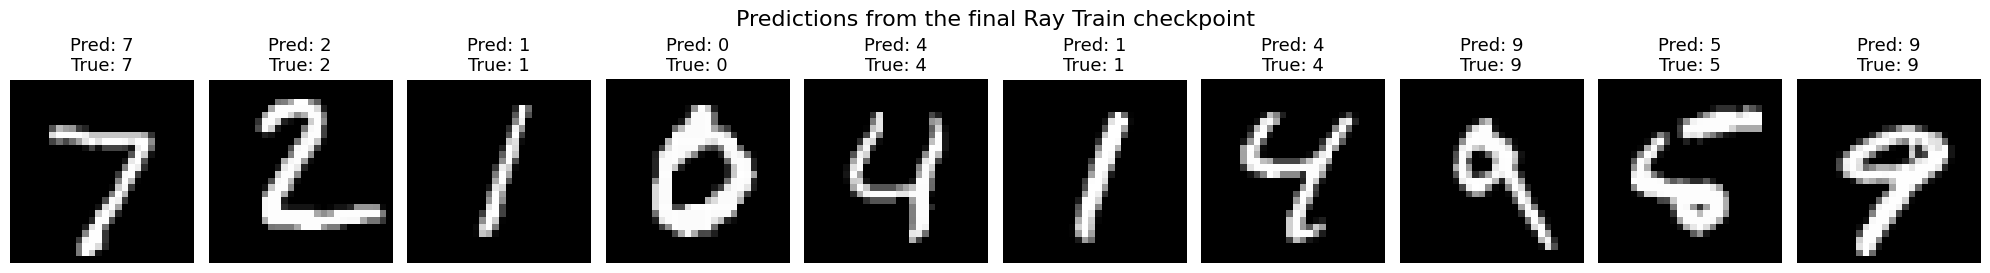

In [17]:
model = build_model()
with result.checkpoint.as_directory() as checkpoint_dir:
    model.load_state_dict(torch.load(os.path.join(checkpoint_dir, "model.pt"), map_location="cpu"))
model.eval()

test_set = MNIST(root=DATA_ROOT, train=False, download=True)
num_images = 10
images = test_set.data[:num_images].numpy()
labels = test_set.targets[:num_images].tolist()

# Apply the same preprocessing that the training pipeline uses.
inputs = torch.as_tensor(preprocess({"image": images})["image"])
with torch.no_grad():
    predictions = model(inputs).argmax(dim=1).tolist()

fig, axes = plt.subplots(1, num_images, figsize=(20, 3))
for ax, image, prediction, label in zip(axes, images, predictions, labels):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Pred: {prediction}\nTrue: {label}", fontsize=13)
    ax.axis("off")
fig.suptitle("Predictions from the final Ray Train checkpoint", fontsize=16)
fig.tight_layout()
plt.show()

## (Optional) Clean up tutorial artifacts

When you finish experimenting, you can remove the datasets, checkpoints, and run artifacts that this tutorial created. This frees shared storage and lets you rerun the tutorial from a clean state.

In [ ]:
import shutil

if os.path.exists(TUTORIAL_ROOT):
    shutil.rmtree(TUTORIAL_ROOT)
    print(f"Deleted directory: {TUTORIAL_ROOT}")
else:
    print(f"Directory doesn't exist: {TUTORIAL_ROOT}")

## Conclusion

In this tutorial, you built a distributed training workflow that treats checkpointing, validation, and failure recovery as work to move off the critical training path, instead of pauses to accept.

You learned how to:
- **Resume from the middle of an epoch** by saving the Ray Data iterator state with the model checkpoint and passing it back to `get_dataset_shard` on restore. You crashed a worker mid-epoch and verified that the interrupted epoch still covered the full training set.
- **Checkpoint asynchronously** with `CheckpointUploadMode.ASYNC`, so that uploads to shared storage don't block training.
- **Validate asynchronously** with a `ValidationConfig`, so that validation runs on separate resources and its metrics are attached to the checkpoint that triggered it.

This tutorial uses MNIST for simplicity, and the same patterns matter most for large-scale workloads:
- Long epochs over large datasets, where restarting an epoch wastes hours of GPU time.
- Spot or preemptible instances, where worker failures are routine.
- Frequent checkpoints of large models, where upload time adds up.
- Validation workloads that don't need the same hardware as training.

By combining Ray Train and Ray Data on Anyscale, you get a training system that keeps GPUs busy and loses as little work as possible when something fails.